# MED source-free transfer: Panasonic 25C -> CMU eVTOL core-seven

This notebook runs `scripts/benchmarks/run_sftnn_transfer_cmu.py`: the
paper-faithful MED method (Shen et al. 2023, Algorithm 1) transferred from
the Panasonic 18650PF 25C source domain to the CMU eVTOL target domain,
compared against a zero-shot (no-adaptation) baseline. It follows the same
conventions as `34_backbone_transfer_panasonic_to_cmu.ipynb`: authenticated
clone/pull from GitHub, Drive-persisted paths from
`configs/paths/colab_drive.yaml`, fine-grained per-(seed, cell, method)
checkpointing with `--resume`, and results read straight back off Drive
rather than trusted to survive only in this runtime.

MED's transfer stage is source-free: it never sees Panasonic data/labels or
real CMU labels. Pseudo-labels come once from the frozen source model's
averaged-head output on CMU's *unlabeled* train-split missions; only the
target feature extractor is trained. Real CMU `soc_dynamic` labels are used
only afterwards, to score the held-out test-split missions -- and
`soc_dynamic` is a development dynamic-capacity reference, not measured
ground truth, so every result row is `label_is_ground_truth=false` /
`formal_benchmark_eligible=false`, matching the rest of this repo's CMU
eVTOL benchmarks.

Every result row also carries a wall-clock timing breakdown (source
pretraining, pseudo-label construction, adaptation, evaluation, and which
device it ran on) -- see the Compute-time section near the end.

## 0. Clone/pull the repo (authenticated) and install

In [4]:
from pathlib import Path
import os, subprocess, sys, tempfile
from urllib.parse import urlunsplit

from google.colab import drive, userdata
drive.mount('/content/drive')

REPO = Path('/content/battery-soc-transfer-benchmark')
REPO_URL = urlunsplit(('https', 'github.com', '/zhangcastle/battery-soc-transfer-benchmark.git', '', ''))
github_token = userdata.get('GITHUB_TOKEN')
if not github_token:
    raise RuntimeError('Add the GITHUB_TOKEN Colab Secret and enable Notebook access')
if REPO.exists() and not (REPO / '.git').exists():
    raise RuntimeError(f'Remove incomplete checkout and rerun: {REPO}')
with tempfile.TemporaryDirectory() as temp_dir:
    askpass = Path(temp_dir) / 'git-askpass.sh'
    askpass.write_text('#!/bin/sh\ncase "$1" in\n*Username*) echo "x-access-token" ;;\n*) printf "%s" "$GITHUB_TOKEN" ;;\nesac\n')
    askpass.chmod(0o700)
    git_env = os.environ.copy()
    git_env.update({'GIT_ASKPASS': str(askpass), 'GIT_TERMINAL_PROMPT': '0', 'GITHUB_TOKEN': github_token})
    command = (['git', '-C', str(REPO), 'pull', '--ff-only'] if (REPO / '.git').exists() else ['git', 'clone', '--depth', '1', REPO_URL, str(REPO)])
    result = subprocess.run(command, env=git_env, text=True, capture_output=True)
del github_token
if result.returncode:
    raise RuntimeError('Authenticated GitHub setup failed; check token permission')
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', str(REPO)], check=True)
os.chdir(REPO)
src_path = str(REPO / 'src')
if src_path not in sys.path:
    sys.path.insert(0, src_path)
print('cwd:', Path.cwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cwd: /content/battery-soc-transfer-benchmark


## Paths (Drive-persisted input/output roots)

Same `configs/paths/colab_drive.yaml` the backbone-transfer notebook uses --
results land on Drive so they survive a Colab disconnect, and the source
code path (`--panasonic-data-root`) doesn't depend on the raw `.mat` files
being baked into the git checkout.

In [5]:
import torch
from battery_benchmark.utils.config import load_yaml

PATHS = load_yaml(REPO / 'configs/paths/colab_drive.yaml')
PANASONIC_ROOT = Path(PATHS['raw_data_root']) / 'Panasonic_18650PF'
CMU_BASE_ROOT = REPO / 'outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_ns_relabel'
CMU_CONDITION_ROOT = REPO / 'outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_extension4_ns_relabel'
CMU_MANIFEST = REPO / 'data/manifests/cmu_evtol/cmu_evtol_supervised_budget_manifest_v0_1_ns_relabel.csv'
RESULT_ROOT = Path(PATHS['output_root']) / 'benchmarks/panasonic_to_cmu_evtol/sftnn_med_transfer_ns_relabel_v2'

for path in (PANASONIC_ROOT, CMU_BASE_ROOT, CMU_CONDITION_ROOT, CMU_MANIFEST):
    assert path.exists(), f'Missing required input: {path}'

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)
print('panasonic root:', PANASONIC_ROOT)
print('results (saved to Drive, survives a disconnect):', RESULT_ROOT)

device: cuda
panasonic root: /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF
results (saved to Drive, survives a disconnect): /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/sftnn_med_transfer_ns_relabel_v2


## Before the full sweep: a smoke test

Run this once after a fresh clone/pull to catch a broken import or a bad
path before committing GPU time to the full sweep. Tiny epoch counts, one
cell, both methods, writes to a throwaway local (non-Drive) output folder.
A loose `--pseudo-threshold` is used here on purpose: with only 2
pretraining epochs the source model's predictions are too noisy for the
paper-default threshold (0.08) to keep any pseudo-labels at all -- that's
expected at this epoch count, not a bug.

In [6]:
smoke_root = Path('/content/sftnn_smoke_test')
subprocess.run(
    [
        sys.executable, '-u', str(REPO / 'scripts/benchmarks/run_sftnn_transfer_cmu.py'),
        '--panasonic-data-root', str(PANASONIC_ROOT),
        '--cmu-base-root', str(CMU_BASE_ROOT),
        '--cmu-condition-root', str(CMU_CONDITION_ROOT),
        '--cmu-manifest', str(CMU_MANIFEST),
        '--output-root', str(smoke_root),
        '--cells', 'VAH01',
        '--methods', 'zero_shot', 'med',
        '--seeds', '42',
        '--source-epochs', '2', '--transfer-epochs', '2',
        '--early-stopping-patience', '1000',
        '--pseudo-threshold', '1.0',
        '--no-save-checkpoints',
        '--device', device,
    ],
    check=True,
)
print('smoke test passed')

smoke test passed


## Setup for the full sweep

`SEEDS = [42]` by default. Defaults match the paper's own MED pretraining
regime (2000 source epochs) and the paper-default confidence threshold
(0.08).

In [7]:
CELLS = ['VAH01', 'VAH17', 'VAH27', 'VAH30', 'VAH15', 'VAH12', 'VAH11']
SEEDS = [42]
SOURCE_EPOCHS, TRANSFER_EPOCHS, BATCH_SIZE = 2000, 200, 64
EARLY_STOPPING_PATIENCE = 30
PSEUDO_THRESHOLD = 0.08

def run_sftnn(methods: list[str]) -> None:
    command = [
        sys.executable, '-u', str(REPO / 'scripts/benchmarks/run_sftnn_transfer_cmu.py'),
        '--panasonic-data-root', str(PANASONIC_ROOT),
        '--cmu-base-root', str(CMU_BASE_ROOT),
        '--cmu-condition-root', str(CMU_CONDITION_ROOT),
        '--cmu-manifest', str(CMU_MANIFEST),
        '--output-root', str(RESULT_ROOT),
        '--cells', *CELLS,
        '--methods', *methods,
        '--seeds', *[str(s) for s in SEEDS],
        '--source-epochs', str(SOURCE_EPOCHS),
        '--transfer-epochs', str(TRANSFER_EPOCHS),
        '--batch-size', str(BATCH_SIZE),
        '--early-stopping-patience', str(EARLY_STOPPING_PATIENCE),
        '--pseudo-threshold', str(PSEUDO_THRESHOLD),
        '--device', device,
        '--resume',
    ]
    subprocess.run(command, check=True)

## Run: zero-shot + MED

With `--resume` and the fine-grained per-(seed, cell, method) checkpointing
in the script, re-running this cell after a disconnect skips everything
already finished.

In [8]:
run_sftnn(['zero_shot', 'med'])

## Optional: DANN+MMD comparison baseline

Split into its own cell -- like the backbone-transfer notebook splits one
cell per backbone -- so a disconnect here doesn't require re-touching the
zero-shot/MED results above. Roughly doubles total runtime versus the cell
above, since it pretrains and adapts a second model. Skip this cell if you
only want the MED vs. zero-shot comparison.

In [9]:
run_sftnn(['dann_mmd'])

## Results -- read straight from Drive

Reads every per-(seed, cell, method) result JSON directly off Drive under
`RESULT_ROOT`, the same way `34_backbone_transfer_panasonic_to_cmu.ipynb`
avoids depending on `cell_metrics.csv` staying fresh -- nothing here
requires re-cloning or re-running the training script, and it's safe to
re-run this section while a sweep above is still going or after a partial
run.

For context (not a direct comparison -- this is the paper's own Panasonic
cross-temperature domain, not CMU eVTOL): Shen et al. (2023) Table VI
reports MED averaging 4.17% MAE / 6.00% RMSE vs. 13.9% / 17.8% for the
source-pretrained baseline and 17.6% / 16.5% for the DANN+MMD baseline in
their own unsupervised cross-temperature setting.

In [10]:
import json as _json
import pandas as pd
from IPython.display import display

method_order = ['zero_shot', 'med', 'dann_mmd']

def load_sftnn_results(result_root: Path) -> pd.DataFrame:
    """Read every per-(seed, cell, method) result JSON directly out of Drive."""
    rows = []
    for result_path in sorted(result_root.glob('seed_*/*/*.json')):
        rows.append(_json.loads(result_path.read_text(encoding='utf-8')))
    df = pd.DataFrame(rows)
    if not df.empty:
        df = df.drop_duplicates(subset=['method', 'cell_id', 'seed'], keep='last')
    return df

results = load_sftnn_results(RESULT_ROOT)
print('rows:', len(results))
results

rows: 21


,method,cell_id,seed,device,med_source_pretrain_seconds,med_source_pretrain_epochs,dann_source_pretrain_seconds,dann_source_pretrain_epochs,pseudo_label_seconds,adapt_seconds,...,epochs_completed,overall_mae_percent,overall_rmse_percent,overall_max_error_percent,overall_bias_percent,overall_r2,mission_macro_mae_percent,mission_macro_rmse_percent,missions,windows
0,dann_mmd,VAH01,42,cuda,50.504414,296,44.563005,281.0,NaN,210.021430,...,200.0,9.432408,11.473060,26.604560,-0.561723,0.252035,7.827811,9.466233,170,1980
1,med,VAH01,42,cuda,50.504414,296,NaN,NaN,1.163255,67.068620,...,144.0,9.344589,10.985873,29.041654,0.380080,0.314209,7.720535,8.669523,170,1980
2,zero_shot,VAH01,42,cuda,50.504414,296,NaN,NaN,NaN,NaN,...,NaN,7.698828,10.963346,34.742528,-3.896376,0.317018,5.745475,8.485105,170,1980
3,dann_mmd,VAH11,42,cuda,50.504414,296,44.563005,281.0,NaN,305.575186,...,200.0,5.960597,9.831988,38.700777,-4.175347,0.333835,4.615583,8.388893,450,5130
4,med,VAH11,42,cuda,50.504414,296,NaN,NaN,2.801403,366.317518,...,200.0,4.758860,7.688391,35.628513,-4.063453,0.592648,3.357448,5.304487,450,5130
5,zero_shot,VAH11,42,cuda,50.504414,296,NaN,NaN,NaN,NaN,...,NaN,5.016134,8.635324,36.071758,-4.174207,0.486126,3.624692,6.644281,450,5130
6,dann_mmd,VAH12,42,cuda,50.504414,296,44.563005,281.0,NaN,306.305708,...,200.0,9.612550,12.850217,38.554144,-9.319280,-0.224507,7.985219,11.645334,471,3566
7,med,VAH12,42,cuda,50.504414,296,NaN,NaN,2.920997,205.137968,...,184.0,10.111680,14.078507,34.962326,-8.830949,-0.469785,8.820622,13.485143,471,3566
8,zero_shot,VAH12,42,cuda,50.504414,296,NaN,NaN,NaN,NaN,...,NaN,10.950763,15.307449,38.790816,-9.226134,-0.737585,9.793097,14.996132,471,3566
9,dann_mmd,VAH15,42,cuda,50.504414,296,44.563005,281.0,NaN,193.317858,...,200.0,8.741884,10.143857,38.694428,3.827620,0.642252,8.165935,9.447438,112,1590


overall_mae_percent                   overall_rmse_percent          \
method             dann_mmd     med zero_shot             dann_mmd     med   
cell_id                                                                      
VAH01                 9.432   9.345     7.699               11.473  10.986   
VAH11                 5.961   4.759     5.016                9.832   7.688   
VAH12                 9.613  10.112    10.951               12.850  14.079   
VAH15                 8.742   8.947     8.397               10.144   9.655   
VAH17                10.498  11.122     8.153               12.876  12.182   
VAH27                 8.576   8.052     7.465                9.949   9.256   
VAH30                 9.482  12.248    17.074               11.247  13.605   

                   
method  zero_shot  
cell_id            
VAH01      10.963  
VAH11       8.635  
VAH12      15.307  
VAH15       9.329  
VAH17      10.624  
VAH27       8.967  
VAH30      18.345

,overall_mae_percent
method,
zero_shot,9.251
med,9.226
dann_mmd,8.900


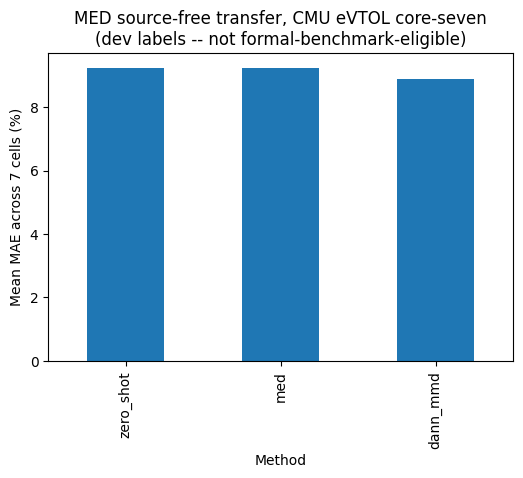

In [11]:
if not results.empty:
    pivot = results.pivot_table(
        index='cell_id', columns='method',
        values=['overall_mae_percent', 'overall_rmse_percent'],
    ).round(3)
    display(pivot)

    curve = (
        results.groupby('method')['overall_mae_percent']
        .mean().reindex([m for m in method_order if m in results['method'].unique()]).round(3)
    )
    display(curve)
    curve.plot(
        kind='bar', figsize=(6, 4), title='MED source-free transfer, CMU eVTOL core-seven\n(dev labels -- not formal-benchmark-eligible)',
        ylabel='Mean MAE across 7 cells (%)', xlabel='Method',
    )
else:
    print('No results yet under', RESULT_ROOT)

## Compute-time results

Every row already has a timing breakdown in seconds:

* `med_source_pretrain_seconds` / `med_source_pretrain_epochs` -- one-off
  per seed (same value repeated across every cell/method row for that
  seed, since pretraining happens once and is then reused).
* `dann_source_pretrain_seconds` / `dann_source_pretrain_epochs` -- only
  populated if the DANN+MMD cell above was run.
* `pseudo_label_seconds` -- time to build the pseudo-labeled target
  dataset (MED only; confidence filtering runs per CMU mission).
* `adapt_seconds` -- time spent actually training (MED's target extractor,
  or DANN+MMD's target extractor + discriminator).
* `eval_seconds` -- time to score the held-out test-split missions.
* `device` -- `cpu` or `cuda`; seconds are meaningless without knowing
  which one produced them, so always read this alongside the timings.

In [12]:
timing_columns = [
    'cell_id', 'method', 'seed', 'device',
    'med_source_pretrain_seconds', 'med_source_pretrain_epochs',
    'dann_source_pretrain_seconds', 'dann_source_pretrain_epochs',
    'pseudo_label_seconds', 'adapt_seconds', 'eval_seconds',
]

if not results.empty:
    timing = results[timing_columns].copy()
    timing['row_seconds'] = timing[
        ['pseudo_label_seconds', 'adapt_seconds', 'eval_seconds']
    ].sum(axis=1, skipna=True)
    display(timing)

    pretrain_once = timing.drop_duplicates(subset=['seed', 'device'])[
        ['seed', 'device', 'med_source_pretrain_seconds', 'dann_source_pretrain_seconds']
    ]
    total_pretrain = pretrain_once[
        ['med_source_pretrain_seconds', 'dann_source_pretrain_seconds']
    ].sum(skipna=True).sum()
    total_transfer_eval = timing['row_seconds'].sum()
    print(f'total pretraining time across seeds: {total_pretrain:.1f}s')
    print(f'total pseudo-label + adapt + eval time across all rows: {total_transfer_eval:.1f}s')
    print(f'grand total (pretrain once per seed + every row): {total_pretrain + total_transfer_eval:.1f}s')
else:
    print('No results yet under', RESULT_ROOT)

,cell_id,method,seed,device,med_source_pretrain_seconds,med_source_pretrain_epochs,dann_source_pretrain_seconds,dann_source_pretrain_epochs,pseudo_label_seconds,adapt_seconds,eval_seconds,row_seconds
0,VAH01,dann_mmd,42,cuda,50.504414,296,44.563005,281.0,NaN,210.021430,0.613862,210.635293
1,VAH01,med,42,cuda,50.504414,296,NaN,NaN,1.163255,67.068620,0.673149,68.905024
2,VAH01,zero_shot,42,cuda,50.504414,296,NaN,NaN,NaN,NaN,0.701040,0.701040
3,VAH11,dann_mmd,42,cuda,50.504414,296,44.563005,281.0,NaN,305.575186,1.690471,307.265657
4,VAH11,med,42,cuda,50.504414,296,NaN,NaN,2.801403,366.317518,1.811841,370.930762
5,VAH11,zero_shot,42,cuda,50.504414,296,NaN,NaN,NaN,NaN,1.804968,1.804968
6,VAH12,dann_mmd,42,cuda,50.504414,296,44.563005,281.0,NaN,306.305708,1.720062,308.025770
7,VAH12,med,42,cuda,50.504414,296,NaN,NaN,2.920997,205.137968,1.821121,209.880086
8,VAH12,zero_shot,42,cuda,50.504414,296,NaN,NaN,NaN,NaN,1.877955,1.877955
9,VAH15,dann_mmd,42,cuda,50.504414,296,44.563005,281.0,NaN,193.317858,0.424364,193.742222


total pretraining time across seeds: 95.1s
total pseudo-label + adapt + eval time across all rows: 2631.8s
grand total (pretrain once per seed + every row): 2726.9s


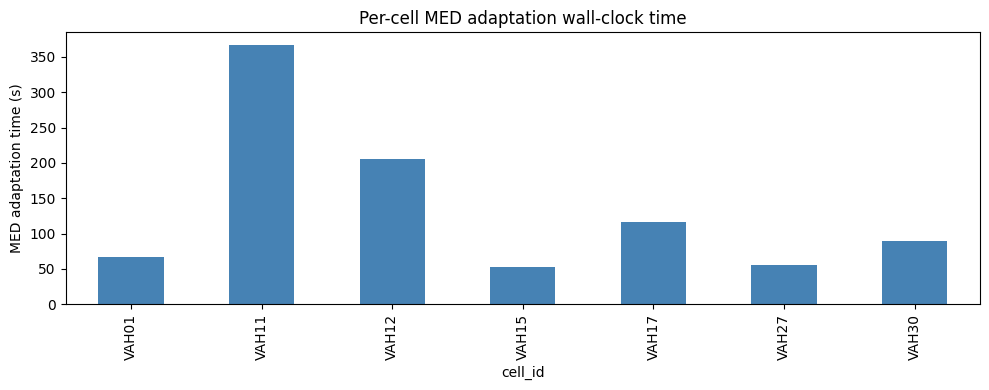

In [13]:
import matplotlib.pyplot as plt

if not results.empty:
    med_rows = results[results['method'] == 'med']
    if not med_rows.empty:
        ax = med_rows.set_index('cell_id')['adapt_seconds'].plot(
            kind='bar', figsize=(10, 4), color='steelblue'
        )
        ax.set_ylabel('MED adaptation time (s)')
        ax.set_title('Per-cell MED adaptation wall-clock time')
        plt.tight_layout()
        plt.show()
    else:
        print("No 'med' rows yet")
else:
    print('No results yet under', RESULT_ROOT)

## Diagnostics: overall metrics, negative transfer, phase-level effects

Everything below is read straight back from what the script already wrote
under `RESULT_ROOT` -- `cell_metrics.csv`-equivalent per-row results
(already loaded into `results` above), `phase_metrics.csv`,
`phase_transfer_effects.csv`, and `training_history.csv` -- nothing here
re-runs the model or recomputes a metric from scratch. Mirrors the
diagnostics section in `33_bian_dtnn_panasonic25_to_cmu.ipynb` and
`36_liu_darm_transfer_panasonic_to_cmu.ipynb`, adapted for SFTNN's two
independent adapted methods (MED and DANN+MMD), each compared against
`zero_shot` separately.

### Overall metrics + delta vs. zero-shot, and cell-level negative transfer

The mean-MAE bar chart above (one number per method, averaged across all
7 cells) hides how much any individual cell got WORSE under adaptation --
a method can look good on average while still making a third of the cells
worse. The table below shows every cell individually and counts negative
transfer explicitly; never just the 7-cell average.

In [14]:
def negative_transfer_table(results: pd.DataFrame, adapted_method: str) -> pd.DataFrame:
    """Per-cell (adapted_method - zero_shot) delta for overall MAE/RMSE.
    delta > 0 means this cell's adaptation made it WORSE than zero-shot,
    i.e. negative transfer -- read directly off cell_metrics-equivalent
    rows already loaded into `results`, never re-evaluated."""
    zero_shot = results.loc[results['method'] == 'zero_shot', ['cell_id', 'seed', 'overall_mae_percent', 'overall_rmse_percent']]
    adapted = results.loc[results['method'] == adapted_method, ['cell_id', 'seed', 'overall_mae_percent', 'overall_rmse_percent']]
    if zero_shot.empty or adapted.empty:
        return pd.DataFrame()
    merged = zero_shot.merge(adapted, on=['cell_id', 'seed'], suffixes=('_zero_shot', '_adapted'))
    merged['delta_mae_percent'] = merged['overall_mae_percent_adapted'] - merged['overall_mae_percent_zero_shot']
    merged['delta_rmse_percent'] = merged['overall_rmse_percent_adapted'] - merged['overall_rmse_percent_zero_shot']
    merged['negative_transfer_mae'] = merged['delta_mae_percent'] > 0
    merged['negative_transfer_rmse'] = merged['delta_rmse_percent'] > 0
    return merged

if not results.empty:
    for adapted_method in ['med', 'dann_mmd']:
        table = negative_transfer_table(results, adapted_method)
        if table.empty:
            print(f"No '{adapted_method}' rows yet")
            continue
        display(table[[
            'cell_id', 'seed',
            'overall_mae_percent_zero_shot', 'overall_mae_percent_adapted', 'delta_mae_percent',
            'overall_rmse_percent_zero_shot', 'overall_rmse_percent_adapted', 'delta_rmse_percent',
            'negative_transfer_mae', 'negative_transfer_rmse',
        ]].round(3))
        n_cells = len(table)
        n_negative_mae = int(table['negative_transfer_mae'].sum())
        n_negative_rmse = int(table['negative_transfer_rmse'].sum())
        print(
            f"{adapted_method}: {n_negative_mae}/{n_cells} cells "
            f"({100 * n_negative_mae / n_cells:.0f}%) show negative transfer on MAE, "
            f"{n_negative_rmse}/{n_cells} ({100 * n_negative_rmse / n_cells:.0f}%) on RMSE"
        )
else:
    print('No results yet under', RESULT_ROOT)

,cell_id,seed,overall_mae_percent_zero_shot,overall_mae_percent_adapted,delta_mae_percent,overall_rmse_percent_zero_shot,overall_rmse_percent_adapted,delta_rmse_percent,negative_transfer_mae,negative_transfer_rmse
0,VAH01,42,7.699,9.345,1.646,10.963,10.986,0.023,True,True
1,VAH11,42,5.016,4.759,-0.257,8.635,7.688,-0.947,False,False
2,VAH12,42,10.951,10.112,-0.839,15.307,14.079,-1.229,False,False
3,VAH15,42,8.397,8.947,0.551,9.329,9.655,0.326,True,True
4,VAH17,42,8.153,11.122,2.969,10.624,12.182,1.557,True,True
5,VAH27,42,7.465,8.052,0.587,8.967,9.256,0.289,True,True
6,VAH30,42,17.074,12.248,-4.827,18.345,13.605,-4.739,False,False


med: 4/7 cells (57%) show negative transfer on MAE, 4/7 (57%) on RMSE


,cell_id,seed,overall_mae_percent_zero_shot,overall_mae_percent_adapted,delta_mae_percent,overall_rmse_percent_zero_shot,overall_rmse_percent_adapted,delta_rmse_percent,negative_transfer_mae,negative_transfer_rmse
0,VAH01,42,7.699,9.432,1.734,10.963,11.473,0.510,True,True
1,VAH11,42,5.016,5.961,0.944,8.635,9.832,1.197,True,True
2,VAH12,42,10.951,9.613,-1.338,15.307,12.850,-2.457,False,False
3,VAH15,42,8.397,8.742,0.345,9.329,10.144,0.815,True,True
4,VAH17,42,8.153,10.498,2.345,10.624,12.876,2.252,True,True
5,VAH27,42,7.465,8.576,1.111,8.967,9.949,0.983,True,True
6,VAH30,42,17.074,9.482,-7.593,18.345,11.247,-7.098,False,False


dann_mmd: 5/7 cells (71%) show negative transfer on MAE, 5/7 (71%) on RMSE


### Phase-level metrics and transfer effects (take_off / cruise / landing)

`phase_metrics.csv` and `phase_transfer_effects.csv` are written once per
invocation by the script, read back here from `RESULT_ROOT` directly
(restricted to the three flight phases; every value is exactly
recomputable from `test_predictions.parquet`'s own columns). MED and
DANN+MMD are each compared against `zero_shot` separately via the
`reference_method` column -- `delta = adapted - zero_shot`, so
`delta > 0` means negative transfer for that (cell, phase).

In [15]:
phase_metrics_path = RESULT_ROOT / 'phase_metrics.csv'
phase_transfer_effects_path = RESULT_ROOT / 'phase_transfer_effects.csv'

if phase_metrics_path.is_file():
    phase_metrics = pd.read_csv(phase_metrics_path)
    display(phase_metrics.round(3))
else:
    phase_metrics = pd.DataFrame()
    print('No phase_metrics.csv yet under', RESULT_ROOT)

if phase_transfer_effects_path.is_file():
    phase_transfer_effects = pd.read_csv(phase_transfer_effects_path)
    display(phase_transfer_effects.round(3))

    negative_transfer_summary = (
        phase_transfer_effects
        .groupby(['method', 'mission_phase'])[['negative_transfer_mae', 'negative_transfer_rmse']]
        .mean()
        .round(3)
    )
    print('Fraction of (cell x condition) pairs showing negative transfer, by method and phase:')
    display(negative_transfer_summary)
else:
    phase_transfer_effects = pd.DataFrame()
    print('No phase_transfer_effects.csv yet under', RESULT_ROOT)

,cell_id,condition,method,mission_phase,n_points,n_missions,mae_percent,rmse_percent,mean_signed_error_percent
0,VAH01,baseline protocol,dann_mmd,take_off,12570,170,16.704,17.252,-16.704
1,VAH01,baseline protocol,dann_mmd,cruise,161480,170,8.609,10.593,0.181
2,VAH01,baseline protocol,dann_mmd,landing,4150,166,19.431,19.613,19.431
3,VAH01,baseline protocol,med,take_off,12570,170,14.935,15.355,-14.935
4,VAH01,baseline protocol,med,cruise,161480,170,8.949,10.631,1.783
...,...,...,...,...,...,...,...,...,...
58,VAH30,35 °C chamber,med,cruise,173480,185,11.302,12.269,-11.288
59,VAH30,35 °C chamber,med,landing,4525,181,8.314,8.443,-8.314
60,VAH30,35 °C chamber,zero_shot,take_off,13695,185,32.841,33.447,-32.841
61,VAH30,35 °C chamber,zero_shot,cruise,173480,185,15.760,16.530,-15.760


,cell_id,condition,method,reference_method,mission_phase,zero_shot_mae_percent,adapted_mae_percent,delta_mae_percent,zero_shot_rmse_percent,adapted_rmse_percent,delta_rmse_percent,negative_transfer_mae,negative_transfer_rmse
0,VAH01,baseline protocol,med,zero_shot,take_off,21.869,14.935,-6.935,23.157,15.355,-7.802,False,False
1,VAH01,baseline protocol,med,zero_shot,cruise,6.519,8.949,2.430,9.363,10.631,1.268,True,True
2,VAH01,baseline protocol,med,zero_shot,landing,10.685,7.818,-2.867,11.208,8.410,-2.797,False,False
3,VAH11,20% lower discharge power,med,zero_shot,take_off,18.770,13.213,-5.557,19.613,13.419,-6.194,False,False
4,VAH11,20% lower discharge power,med,zero_shot,cruise,3.797,3.940,0.144,6.960,6.913,-0.047,True,False
5,VAH11,20% lower discharge power,med,zero_shot,landing,9.581,10.175,0.594,11.211,11.037,-0.174,True,False
6,VAH12,short 400 s cruise,med,zero_shot,take_off,28.530,27.298,-1.232,29.833,27.841,-1.992,False,False
7,VAH12,short 400 s cruise,med,zero_shot,cruise,7.004,6.696,-0.308,9.976,9.754,-0.222,False,False
8,VAH12,short 400 s cruise,med,zero_shot,landing,24.226,19.304,-4.922,24.965,20.190,-4.774,False,False
9,VAH15,extended 1000 s cruise,med,zero_shot,take_off,4.139,6.532,2.393,5.159,6.737,1.578,True,True


Fraction of (cell x condition) pairs showing negative transfer, by method and phase:


negative_transfer_mae  negative_transfer_rmse
method   mission_phase                                               
dann_mmd cruise                         0.857                   0.857
         landing                        0.714                   0.714
         take_off                       0.429                   0.429
med      cruise                         0.714                   0.571
         landing                        0.143                   0.000
         take_off                       0.286                   0.286

### Training curves -- MED and DANN+MMD shown separately

MED's adaptation loss (`soc`, `dis`, `total`) and DANN+MMD's adaptation
loss (`estimate`, `adversarial`, `mmd`, `total`) are different objectives
over different fields -- plotted on separate axes here so they are never
visually or numerically conflated. Where the diagnostic-only validation
probe ran (`validation_evaluated=True`), its MAE/RMSE trajectory is shown
alongside -- this is a READ-ONLY diagnostic against the manifest's
existing validation-split missions; it never fed back into training,
pseudo-labeling, the scheduler, early stopping, checkpoint, or model
selection (see `run_metadata.json`'s
`target_validation_labels_used_for_diagnostics`/`_for_training`/
`_for_checkpoint_selection` flags).

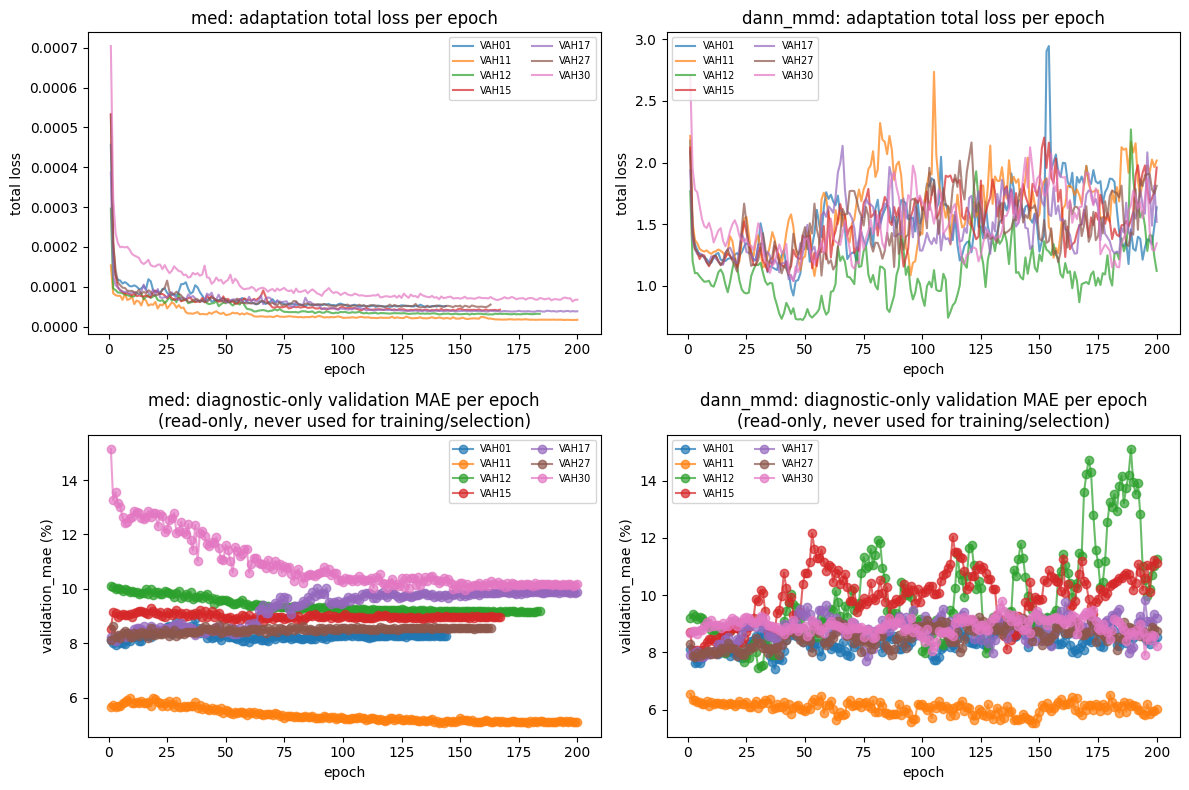

In [16]:
training_history_path = RESULT_ROOT / 'training_history.csv'

if training_history_path.is_file():
    training_history = pd.read_csv(training_history_path)
else:
    training_history = pd.DataFrame()
    print('No training_history.csv yet under', RESULT_ROOT)

if not training_history.empty:
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for col, method in enumerate(['med', 'dann_mmd']):
        rows = training_history.loc[training_history['method'] == method]
        loss_ax, val_ax = axes[0, col], axes[1, col]
        if rows.empty:
            loss_ax.set_title(f'{method}: no adaptation rows yet')
            val_ax.axis('off')
            continue
        for cell_id, cell_rows in rows.groupby('cell_id'):
            loss_field = 'total'  # both MED ({soc,dis,total}) and DANN+MMD ({estimate,adversarial,mmd,total}) share 'total'
            loss_ax.plot(cell_rows['epoch'], cell_rows[loss_field], label=str(cell_id), alpha=0.7)
        loss_ax.set_title(f'{method}: adaptation total loss per epoch')
        loss_ax.set_xlabel('epoch')
        loss_ax.set_ylabel('total loss')
        loss_ax.legend(fontsize=7, ncol=2)

        evaluated = rows.loc[rows['validation_evaluated'] == True]
        if evaluated.empty:
            val_ax.set_title(f'{method}: no validation diagnostics recorded')
            val_ax.axis('off')
            continue
        for cell_id, cell_rows in evaluated.groupby('cell_id'):
            val_ax.plot(cell_rows['epoch'], cell_rows['validation_mae'], marker='o', label=str(cell_id), alpha=0.7)
        val_ax.set_title(f'{method}: diagnostic-only validation MAE per epoch\n(read-only, never used for training/selection)')
        val_ax.set_xlabel('epoch')
        val_ax.set_ylabel('validation_mae (%)')
        val_ax.legend(fontsize=7, ncol=2)
    plt.tight_layout()
    plt.show()
else:
    print('No adaptation training history yet under', RESULT_ROOT)

### Source pretraining curves and clarified per-stage timing

Source pretraining (`med_source_pretrain` / `dann_mmd_source_pretrain`)
happens ONCE per seed, not once per cell -- the timing table in the
"Compute-time results" section above already de-duplicates it
(`pretrain_once = timing.drop_duplicates(subset=['seed', 'device'])`)
before summing, so it is never double-counted across the seven cells.
This section shows the pretraining loss curve itself (from
`training_history.csv`, one line per seed) plus each stage's own total
and per-epoch/cumulative real wall-clock `runtime_seconds` -- source
pretraining, pseudo-labeling, adaptation, and evaluation each have their
own independent timing; they are never summed into a single
undifferentiated number.

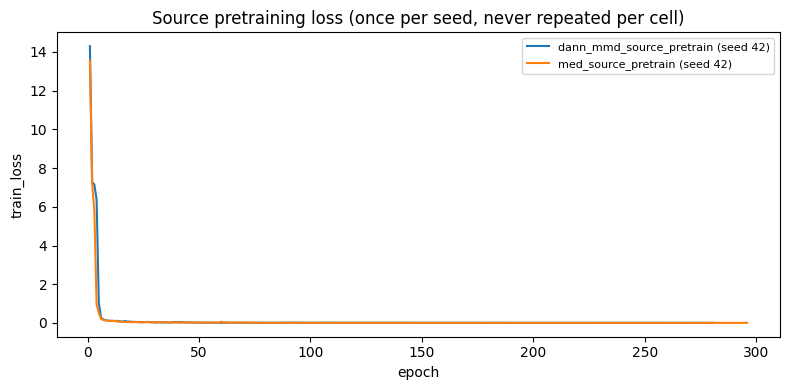

Source pretraining: per-epoch real wall-clock runtime_seconds, summed once per seed:


,,total_seconds,epochs
method,seed,,
dann_mmd_source_pretrain,42,43.353,281
med_source_pretrain,42,49.239,296


Adaptation: per-epoch real wall-clock runtime_seconds, per (method, cell):


total_seconds  epochs
method   cell_id                       
dann_mmd VAH01          154.470     200
         VAH11          155.352     200
         VAH12          155.407     200
         VAH15          155.759     200
         VAH17          154.913     200
         VAH27          154.895     200
         VAH30          155.007     200
med      VAH01           23.638     144
         VAH11          202.367     200
         VAH12           52.332     184
         VAH15           19.610     167
         VAH17           43.496     200
         VAH27           20.446     163
         VAH30           23.511     200

,method,cell_id,epoch,runtime_seconds,cumulative_seconds
3225,med,VAH30,191,0.127070,22.453092
3226,med,VAH30,192,0.119588,22.572680
3227,med,VAH30,193,0.123867,22.696547
3228,med,VAH30,194,0.116639,22.813186
3229,med,VAH30,195,0.116440,22.929625
3230,med,VAH30,196,0.116371,23.045996
3231,med,VAH30,197,0.115539,23.161535
3232,med,VAH30,198,0.115928,23.277463
3233,med,VAH30,199,0.116618,23.394081
3234,med,VAH30,200,0.117316,23.511397


In [17]:
if not training_history.empty:
    pretrain_rows = training_history.loc[
        training_history['method'].isin(['med_source_pretrain', 'dann_mmd_source_pretrain'])
    ]
    if not pretrain_rows.empty:
        fig, ax = plt.subplots(figsize=(8, 4))
        for (method, seed), rows in pretrain_rows.groupby(['method', 'seed']):
            ax.plot(rows['epoch'], rows['train_loss'], label=f'{method} (seed {seed})')
        ax.set_xlabel('epoch')
        ax.set_ylabel('train_loss')
        ax.set_title('Source pretraining loss (once per seed, never repeated per cell)')
        ax.legend(fontsize=8)
        plt.tight_layout()
        plt.show()

        pretrain_runtime = (
            pretrain_rows.groupby(['method', 'seed'])['runtime_seconds']
            .agg(['sum', 'count']).rename(columns={'sum': 'total_seconds', 'count': 'epochs'})
        )
        print('Source pretraining: per-epoch real wall-clock runtime_seconds, summed once per seed:')
        display(pretrain_runtime.round(3))
    else:
        print('No source-pretraining history rows yet')

    adapt_rows = training_history.loc[training_history['method'].isin(['med', 'dann_mmd'])]
    if not adapt_rows.empty:
        adapt_runtime = (
            adapt_rows.groupby(['method', 'cell_id'])['runtime_seconds']
            .agg(['sum', 'count']).rename(columns={'sum': 'total_seconds', 'count': 'epochs'})
        )
        print('Adaptation: per-epoch real wall-clock runtime_seconds, per (method, cell):')
        display(adapt_runtime.round(3))
        cumulative = adapt_rows.sort_values(['method', 'cell_id', 'epoch']).copy()
        cumulative['cumulative_seconds'] = cumulative.groupby(['method', 'cell_id'])['runtime_seconds'].cumsum()
        display(cumulative[['method', 'cell_id', 'epoch', 'runtime_seconds', 'cumulative_seconds']].tail(10))
else:
    print('No training history yet under', RESULT_ROOT)